# Hands-on 32 (Bab 13): Memonitor Perubahan Distribusi Data (Data Drift)

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 13.

Pemantauan drift sederhana namun realistis: bandingkan mean/std/median dan histogram
antara baseline (14 hari pertama) dan current (7 hari terakhir), lalu beri indikator
drift dengan ambang sederhana.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Monitoring Distribusi + Indikator Drift

[INFO] Baseline: 2016 baris, Current: 1009 baris
=== Ringkasan perubahan distribusi ===
      feature  baseline_mean  current_mean  mean_shift  baseline_std  current_std  std_shift  baseline_median  current_median
temperature_c         24.843        25.510       0.667         2.523        2.513     -0.011            24.85           25.49
 humidity_pct         67.772        67.628      -0.144         2.917        2.793     -0.124            67.68           67.63

=== Indikator drift ===
[INFO] temperature_c: tidak ada drift mencolok (+0.667)
[INFO] humidity_pct: tidak ada drift mencolok (-0.144)
[SUKSES] outputs/figures/dist_compare_temperature_c.png
[SUKSES] outputs/figures/dist_compare_humidity_pct.png



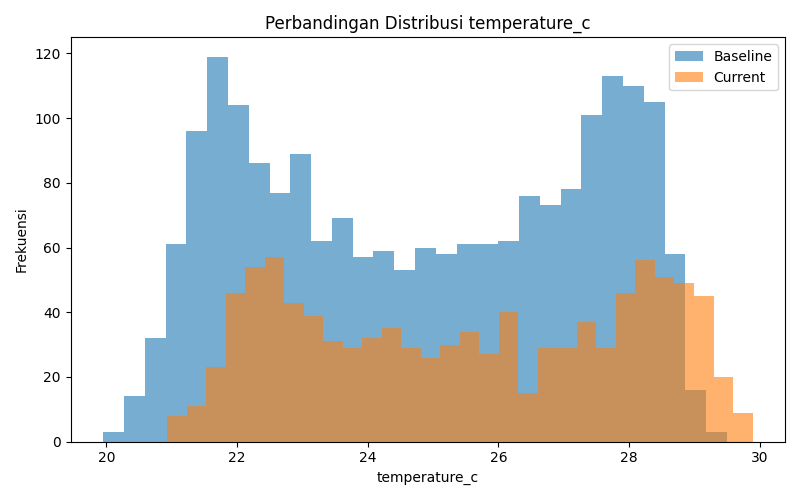

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/monitor_data_distribution.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/dist_compare_temperature_c.png")

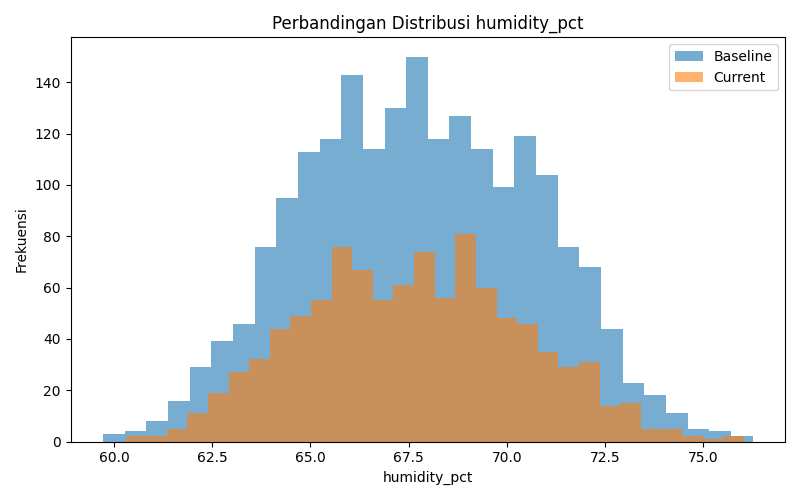

In [3]:
Image("outputs/figures/dist_compare_humidity_pct.png")

## Penutup

Pada dataset ini mean suhu bergeser +0.67 C dan kelembaban -0.14, keduanya di bawah
ambang 1.0 sehingga tidak ada drift mencolok: distribusi masih stabil. Pada operasional
nyata, indikator seperti ini menjadi alarm awal untuk investigasi (misal ventilasi
berubah atau model mulai sering salah). Hasil tersimpan di
`outputs/reports/data_distribution_monitor.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 34 dalam urutan buku) agar dapat dijadikan panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 9. Insight penting Hands-on 32

Latihan ini mengajarkan bahwa:

- drift bisa dideteksi tanpa framework rumit,
- monitoring distribusi fitur utama adalah langkah minimum yang realistis,
- dan perubahan distribusi input sering menjadi tanda awal penurunan
performa model.